# CMRM Assignment No. 2

In [1]:
import os
import librosa
import scipy
import sklearn # pip install sklearn
import numpy as np
import pandas as pd # pip install pandas
import matplotlib.pyplot as plt
import IPython.display as ipd
from tqdm import tqdm # pip install tqdm
from sklearn.linear_model import LogisticRegression
from mutagen.easyid3 import EasyID3 # pip install mutagen

## Question 1

In [2]:
train_path = 'sonics/train'
test_path = 'sonics/test'

# -------------------------------------------------- #
# Train set
fake_path = os.path.join(train_path, 'fake')
real_path = os.path.join(train_path, 'real')

# Function that returns a list of files (hidden files excluded) present in the given path
def list_audio_files(path):
    return sorted(
        [file for file in os.listdir(path) if not file.startswith('.')] # hidden files excluded
    )

fake_train = list_audio_files(fake_path) # files in sonics/test/fake

# Print the number of files
print("Number of fake tracks in the train set:", len(fake_train))


real_train = list_audio_files(real_path) # files in sonics/test/real

# Print the number of files
print("Number of real tracks in the train set:", len(real_train))



# -------------------------------------------------- #
# Test set

test_set = list_audio_files(test_path)

# Print the number of files
print("Number of tracks in the test set:", len(test_set))

Number of fake tracks in the train set: 485
Number of real tracks in the train set: 485
Number of tracks in the test set: 515


In [3]:
print(len(fake_train))
print(len(real_train))

485
485


The number of tracks for testing present in *test* directory is:

In [4]:
print(len(test_set))

515


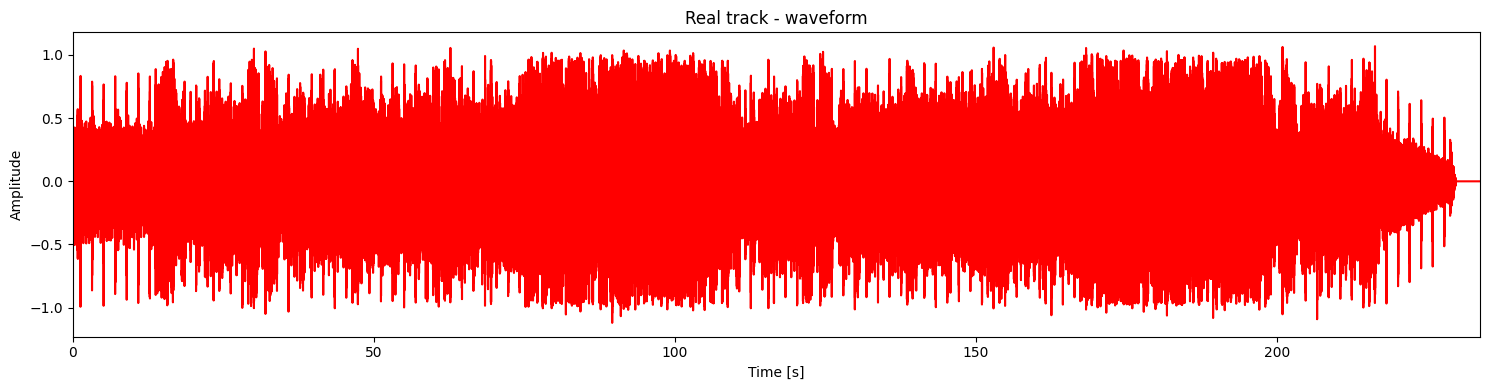

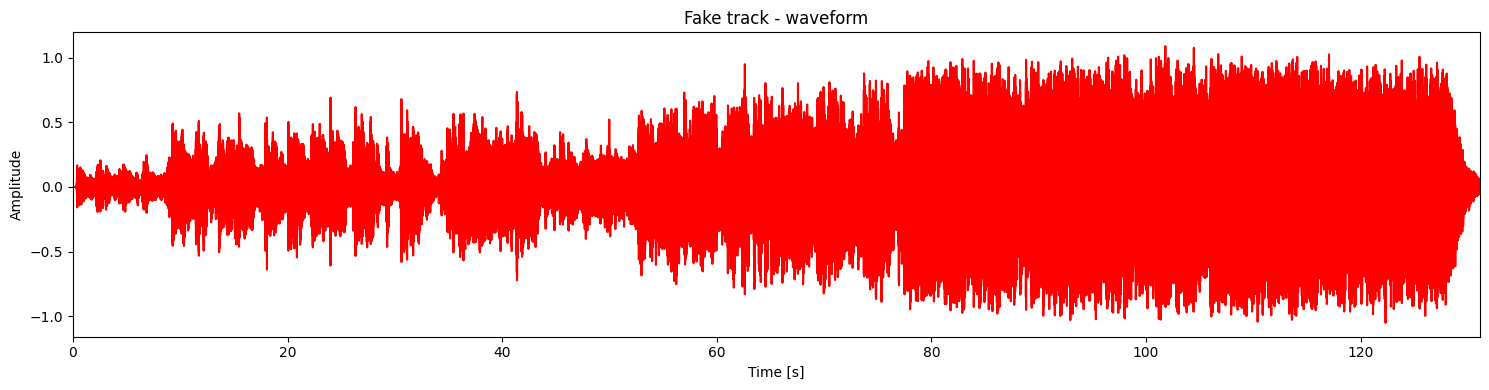

In [5]:
# Load signal fake_train[0] - Time domain
Fs = 22050

# Path of the first real audio file
real_filename = os.path.join(real_path, real_train[0])

# Path of the first fake audio file
fake_filename = os.path.join(fake_path, fake_train[0])

real_track, _ = librosa.load(real_filename, sr = Fs, mono = True)
fake_track, _ = librosa.load(fake_filename, sr = Fs, mono = True)

def plot_audio_signal (signal, Fs, text = ''):

    # Time axis definition
    time_axis = np.arange(len(signal)) / Fs

    # Plot
    plt.figure(figsize = (15, 4))
    plt.plot(time_axis, signal, color = 'red')
    plt.xlim([time_axis[0], time_axis[-1]])
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.title(text)
    plt.tight_layout()
    plt.show()

plot_audio_signal(real_track, Fs, text = 'Real track - waveform')
plot_audio_signal(fake_track, Fs, text = 'Fake track - waveform')

Play the first real track of the dataset.

In [6]:
ipd.display(ipd.Audio(real_track, rate = Fs))

Play the first fake track of the dataset.

In [7]:
ipd.display(ipd.Audio(fake_track, rate = Fs))

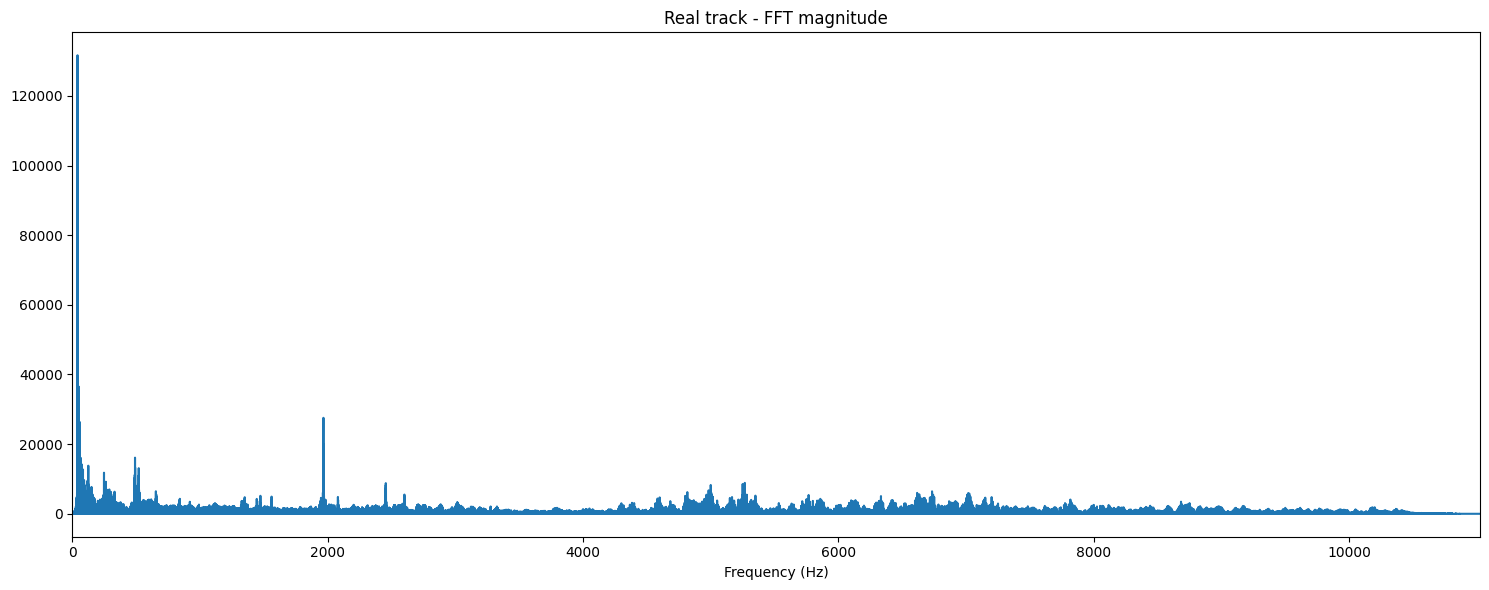

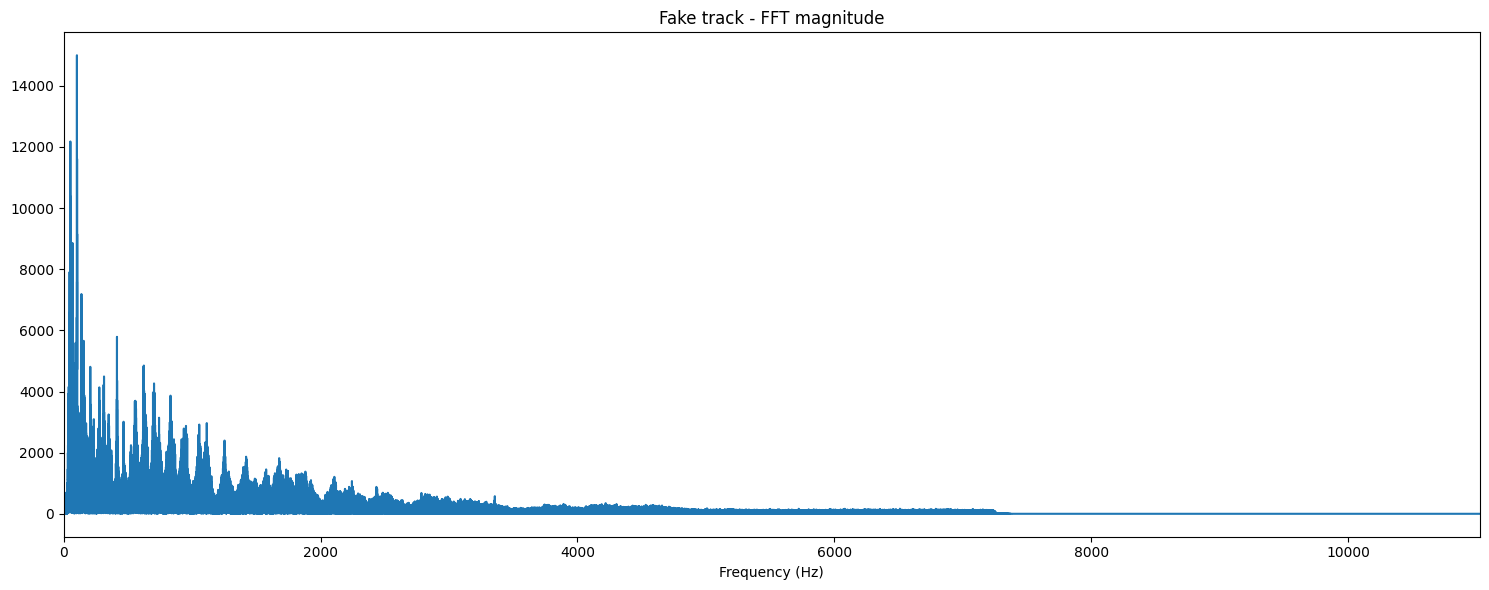

In [8]:
# FFT

# To plot the fft of a signal
def plot_fft(sig, freq_axis, Fs, title = ''):
    plt.figure(figsize = (15, 6))
    plt.plot(freq_axis, sig)
    plt.xlim([0, Fs / 2])
    plt.xlabel('Frequency (Hz)')
    plt.title(title)
    plt.tight_layout()
    plt.show()

# FFT parameters
N_real = len(real_track)
N_fake = len(fake_track)

# Real track
X_real = np.abs(np.fft.fft(real_track))
freq_real = np.fft.fftfreq(N_real, d = 1 / Fs)

# Only positive frequencies
X_real = X_real[: N_real // 2]
freq_real = freq_real[: N_real // 2]

# Real track plot
plot_fft(X_real, freq_real, Fs = Fs, title = 'Real track - FFT magnitude')

# Fake track
X_fake = np.abs(np.fft.fft(fake_track))
freq_fake = np.fft.fftfreq(N_fake, d = 1 / Fs)

# Only positive frequencies
X_fake = X_fake[: N_fake // 2]
freq_fake = freq_fake[: N_fake // 2]

# Fake track plot
plot_fft(X_fake, freq_fake, Fs = Fs, title ='Fake track - FFT magnitude')




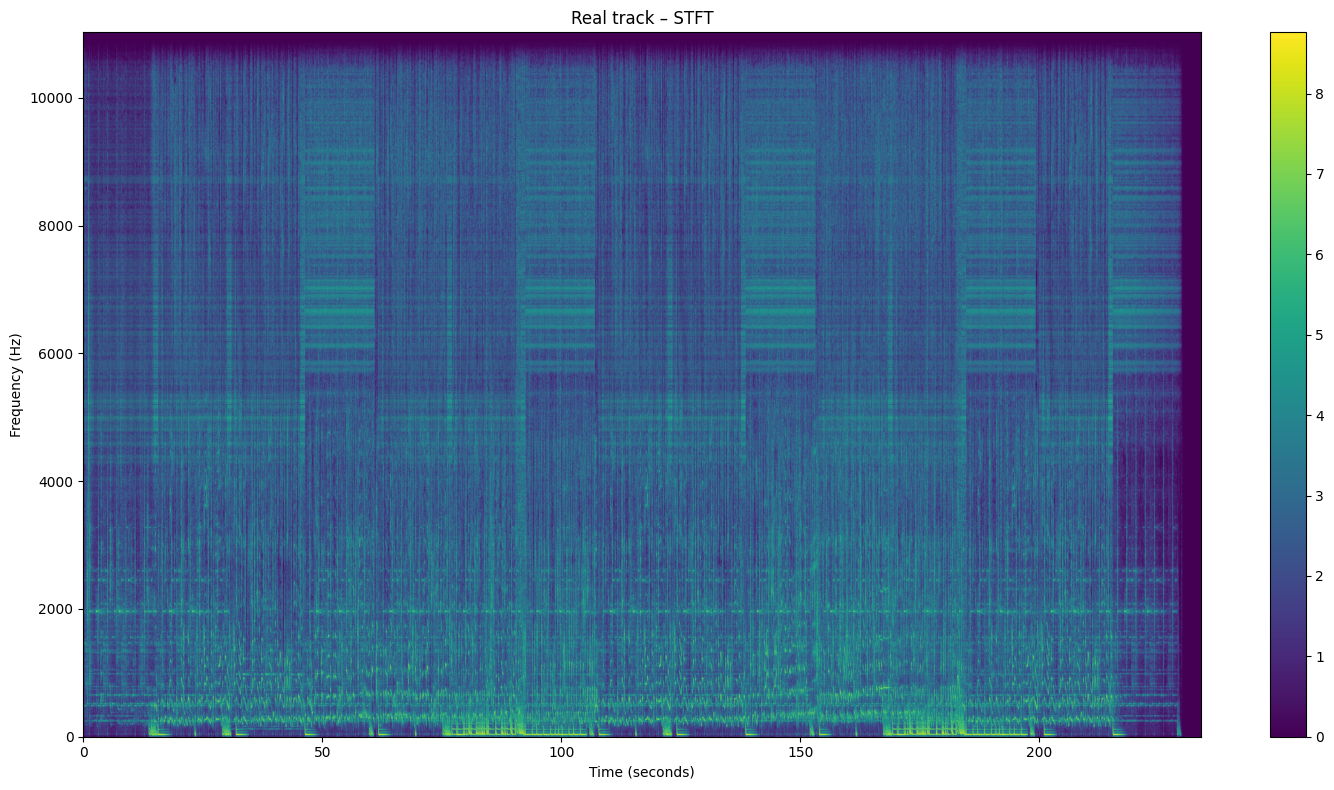

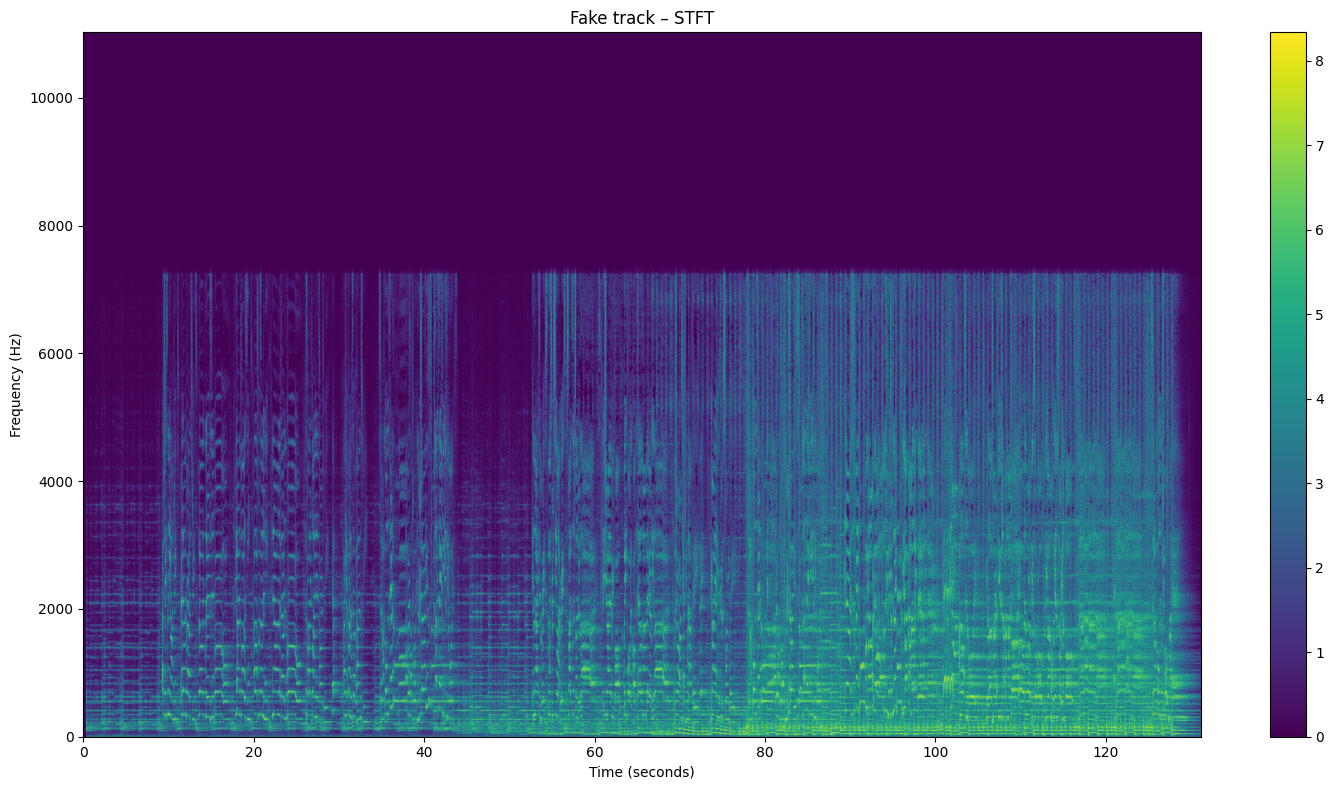

In [9]:
def plot_stft(x, Fs, N = 4096, H = 1024, title = ''):
    X = librosa.stft(x, n_fft = N, hop_length = H, win_length = N, window = 'hann')
    Y = np.log(1 + 10 * np.abs(X))
    
    time_axis = np.arange(X.shape[1]) / (Fs / H)
    frequency_axis = np.arange(X.shape[0]) / (N / Fs)
    
    x_ext = (time_axis[1] - time_axis[0]) / 2
    y_ext = (frequency_axis[1] - frequency_axis[0]) / 2
    image_extent = [time_axis[0] - x_ext, time_axis[-1] + x_ext, 
                    frequency_axis[0] - y_ext, frequency_axis[-1] - y_ext]
    
    plt.figure(figsize = (15,8))
    im = plt.imshow(Y, extent = image_extent, aspect = 'auto', origin = 'lower')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Frequency (Hz)')
    plt.ylim([0, Fs / 2])
    plt.title(title)
    plt.colorbar(im)
    plt.tight_layout()
    plt.show()


N = 4096
H = 1024

plot_stft(real_track, Fs, N = N, H = H, title = 'Real track – STFT')
plot_stft(fake_track, Fs, N = N, H = H, title = 'Fake track – STFT')

## Question 2

In [10]:
# Testing functions
from utils import lower_envelope, max_normalise, curve_profile

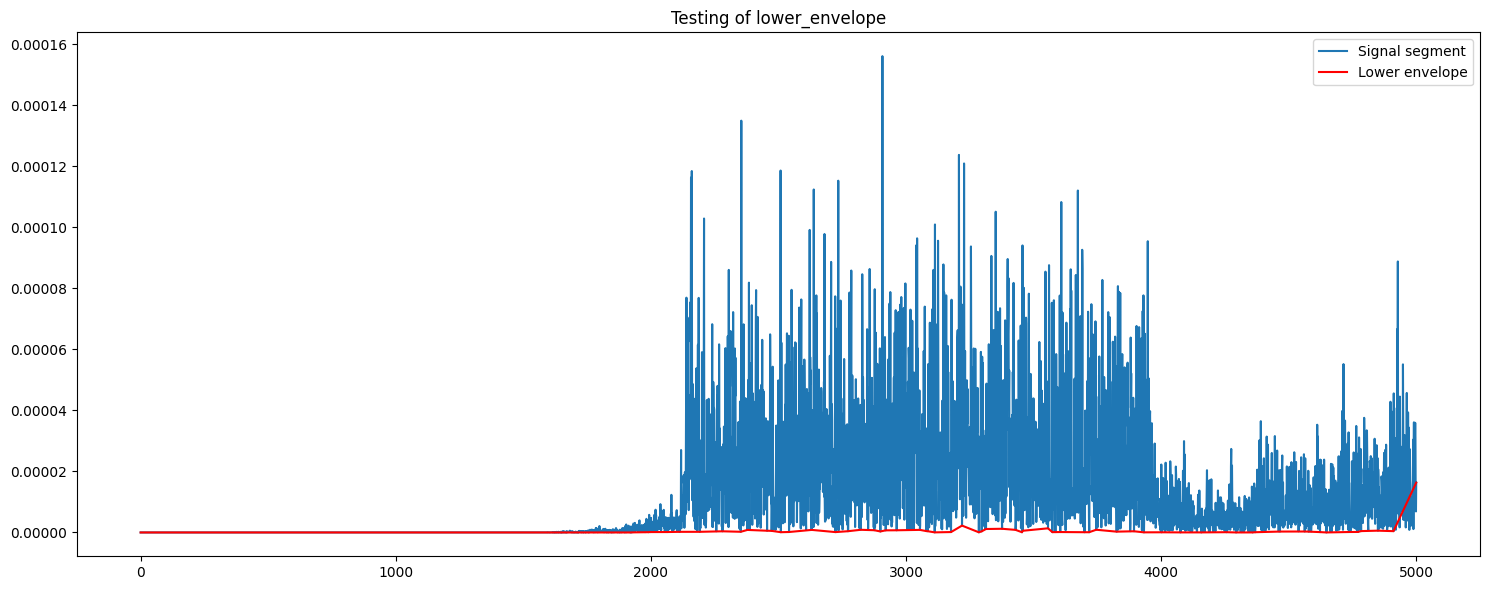

In [11]:
# lower_envelope testing
trackSegment = np.abs(real_track[:5000])
idx, hull = lower_envelope(trackSegment, area = 100)

plt.figure(figsize=(15,6))
plt.plot(trackSegment, label = 'Signal segment')
plt.plot(idx, hull, 'r', label = 'Lower envelope')
plt.title("Testing of lower_envelope")
plt.legend()
plt.tight_layout()
plt.show()

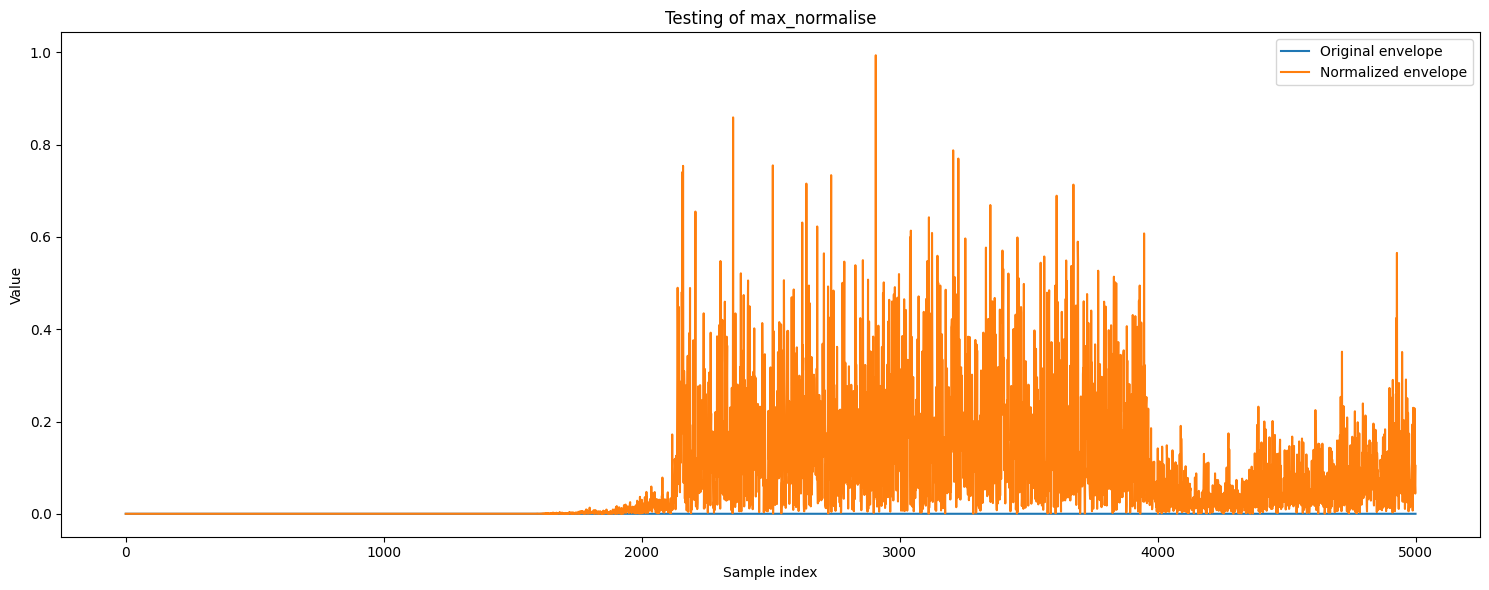

In [12]:
# max_normalise testing
trackSegment = real_track[:5000]
env = np.abs(trackSegment)
env_norm = max_normalise(env)

plt.figure(figsize = (15,6))
plt.plot(env, label = "Original envelope")
plt.plot(env_norm, label = "Normalized envelope")
plt.title("Testing of max_normalise")
plt.xlabel("Sample index")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

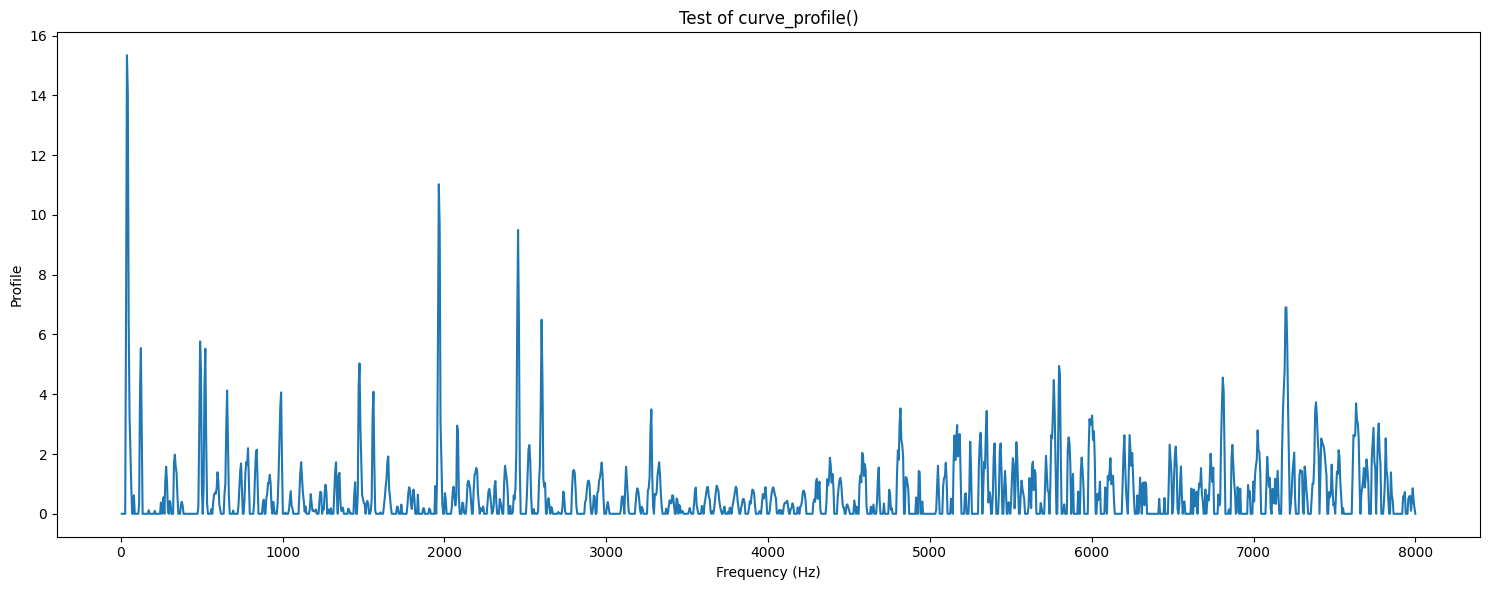

In [13]:
# curve_profile testing
X = librosa.stft(real_track, n_fft = 4096, hop_length = 1024, win_length = 4096, window = 'hann')
mean_spec = np.mean(np.abs(X), axis = 1)
mean_db = 20 * np.log10(mean_spec + 1e-12)
freqs = np.linspace(0, Fs / 2, len(mean_db))

x_, profile = curve_profile(freqs, mean_db, f_range = [0,8000])

plt.figure(figsize = (15,6))
plt.plot(x_, profile)
plt.title("Test of curve_profile()")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Profile")
plt.tight_layout()
plt.show()

In [14]:
def fakeprint(stft, f_range = [0, 16000], fs = 22050):
    """
    Compute the fakeprint feature from an STFT representation.

        Args:
            stft: 2D STFT spectrogram.
            f_range: Frequency range [min_freq, max_freq] over which the
                     curve profile is computed.
            SR: Sampling rate of the original audio signal.

        Returns:
            fp_curve: Normalized fakeprint feature curve extracted from the
                      averaged spectral profile.
    """
    # If the input is not a power spectrogram, it is then computed.
    if np.iscomplexobj(stft):
        stft = np.abs(stft) ** 2

    mag_db = 20 * np.log10(stft + 1e-6) # Conversion to dB scale.

    mean_spectrum = np.mean(mag_db, axis = 1)

    n_bins = mean_spectrum.shape[0]
    x_freq = np.linspace(0, fs / 2, n_bins)

    _, profile = curve_profile(x_freq, mean_spectrum, f_range = f_range)

    fp_curve = max_normalise(profile)

    return fp_curve

In [15]:
# Test fakeprint functions

def test_fakeprint(audio_track, f_range, fs):

    """
    Test the fakeprint feature function

        Args: 
            audio_track: audio track to compute.
            f_range: Frequency range [min_freq, max_freq] over which the
                     curve profile is computed.
            fs: sampling rate of the audio signal.

        Returns: 
            fp: Normalized fakeprint feature curve extracted from the
                averaged spectral profile.
    """

    N = 4096 # As in the previous question
    H = 1024 # As in the previous question

    stft = librosa.stft(audio_track, n_fft = N, hop_length = H) # STFT
    stft_power = np.abs(stft) ** 2 # Conversion to power spectrogram

    fp = fakeprint(stft_power, f_range, fs)

    return fp


def plot_fakeprint_test (fp, title = ''):

    """
    Plots the fakeprint test results

        Args:
            fp: Normalized fakeprint feature curve extracted from the
                averaged spectral profile.
            title: Title of the plot.
    """
    plt.figure(figsize = (15,6))
    plt.plot(fp)
    plt.xlabel('Frequency Bins')
    plt.ylabel('Normalised amplitude')
    plt.title(title)
    plt.show()

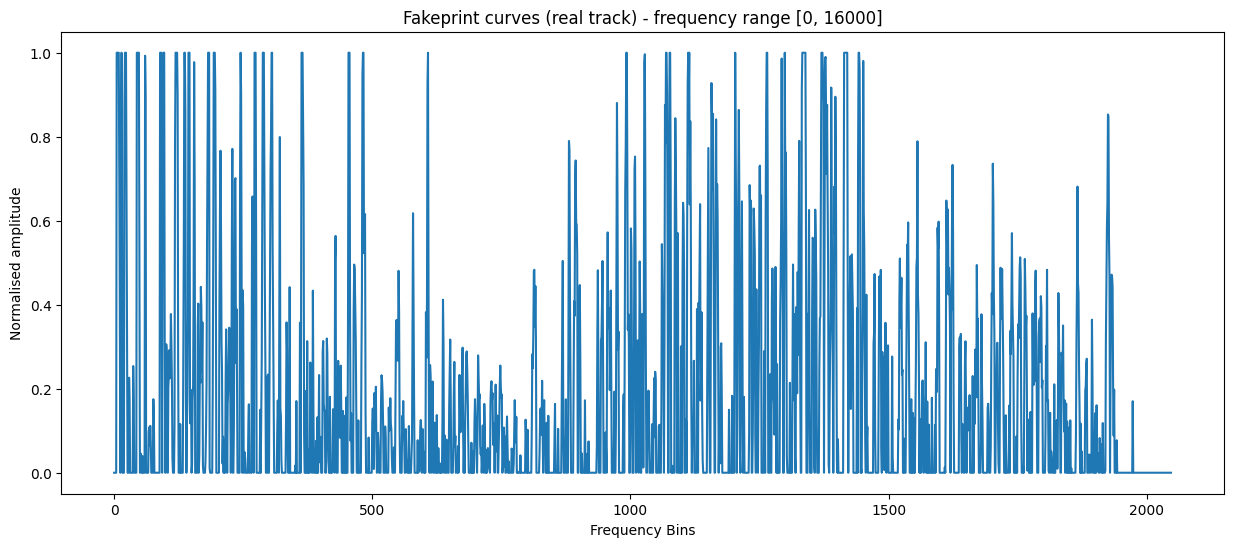

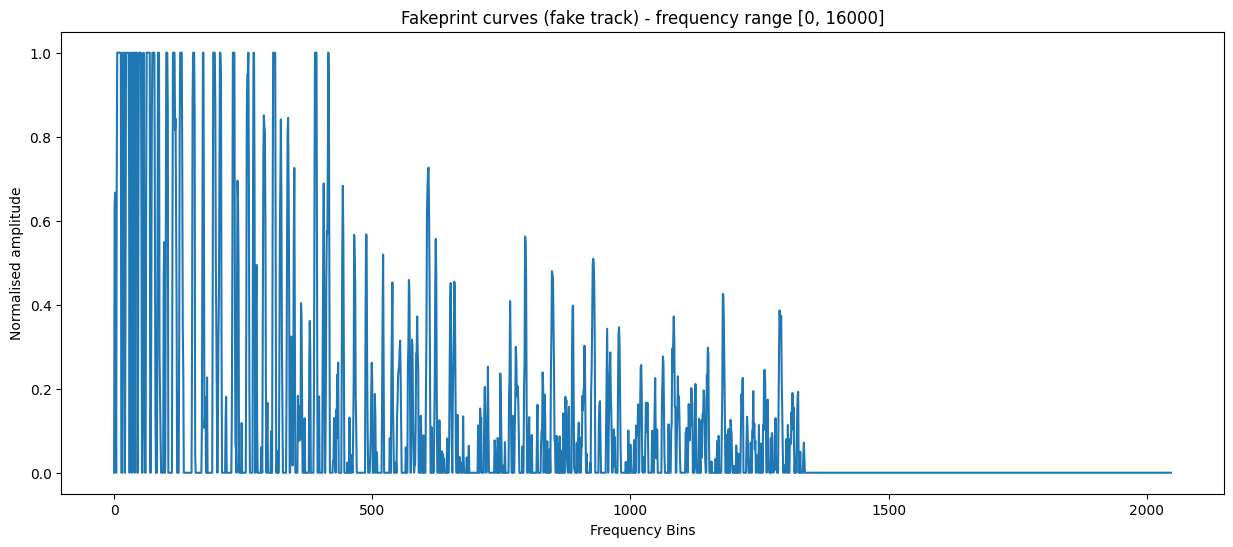

In [16]:
# Fakeprint testing

"""
Test:
    audio track: real track
    f_range: [0, 16000]
"""
fp = test_fakeprint(real_track, f_range = [0, 16000], fs = 22050)
plot_fakeprint_test(fp, title = 'Fakeprint curves (real track) - frequency range [0, 16000]')


"""
Test:
    audio track: fake track
    f_range: [0, 16000]
"""
fp = test_fakeprint(fake_track, f_range = [0, 16000], fs = 22050)
plot_fakeprint_test(fp, title = 'Fakeprint curves (fake track) - frequency range [0, 16000]')

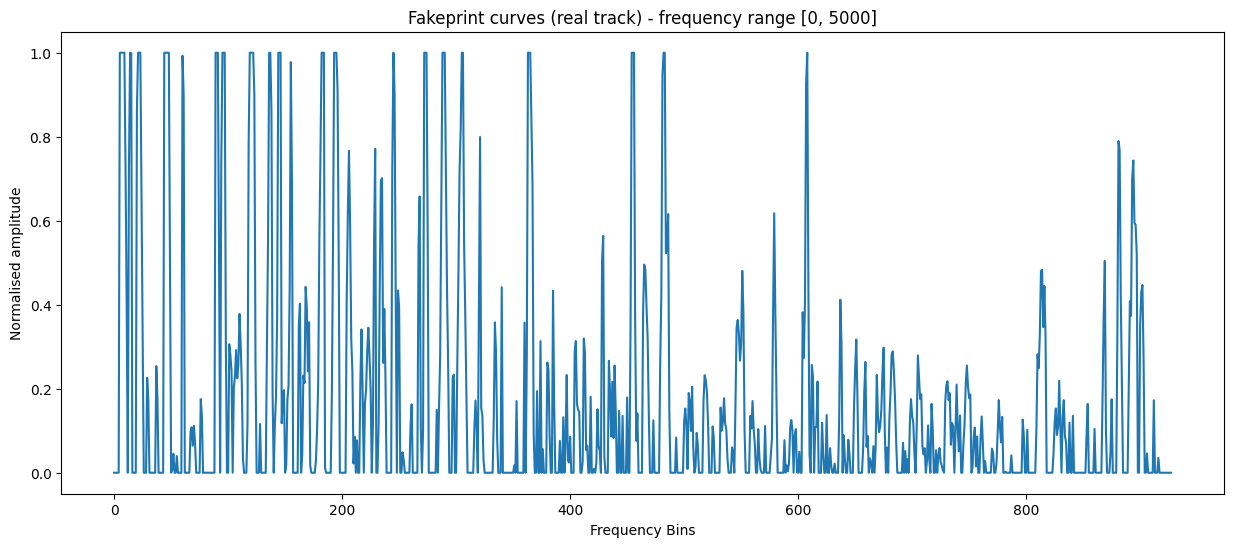

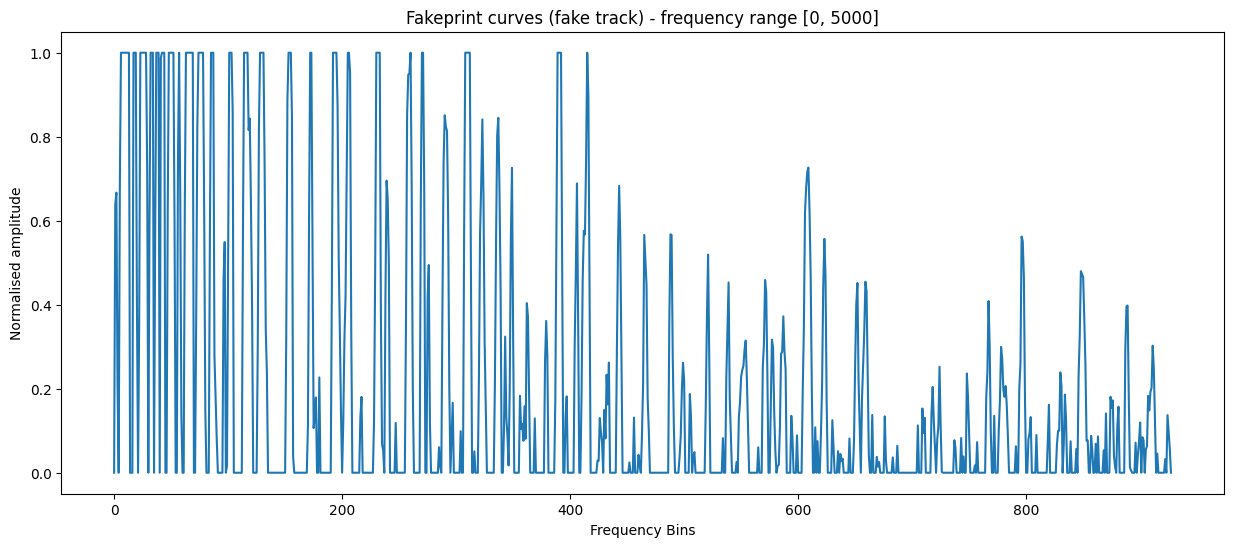

In [17]:
# Fakeprint testing

"""
Test:
    audio track: real track
    f_range: [0, 5000]
"""
fp = test_fakeprint(real_track, f_range = [0, 5000], fs = 22050)
plot_fakeprint_test(fp, title = 'Fakeprint curves (real track) - frequency range [0, 5000]')


"""
Test:
    audio track: fake track
    f_range: [0, 5000]
"""
fp = test_fakeprint(fake_track, f_range = [0, 5000], fs = 22050)
plot_fakeprint_test(fp, title = 'Fakeprint curves (fake track) - frequency range [0, 5000]')

## Question 3

In [18]:
def compute_feature_vector(filename, Fs = 22050, N = 4096, H = 1024):
    """Compute the feature vector 

    Args:
        filename: Input filename
        Fs: Sampling rate
        N: Window length
        H: Hop size

    Returns:
        f_vector: Feature vector
    """
    # 1) load the audio track
    audio_track, _ = librosa.load(filename, sr = Fs, mono = True)

    # 2) STFT and power spectrogram
    stft = librosa.stft(audio_track, n_fft = N, hop_length = H,
                        win_length = N, window = 'hann')
    stft_power = np.abs(stft) ** 2   # power spectrogram

    # 3) fakeprint as the feature vector
    f_vector = fakeprint(stft_power, f_range = [0, 16000], fs = Fs)

    return f_vector

Feature vector shape: (2048,)
First 10 values of the feature vector: [0.00000000e+00 6.37907207e-01 6.66865402e-01 2.08332041e-01
 3.55271297e-16 6.77919186e-01 9.99999800e-01 9.99999800e-01
 9.99999800e-01 9.99999800e-01]


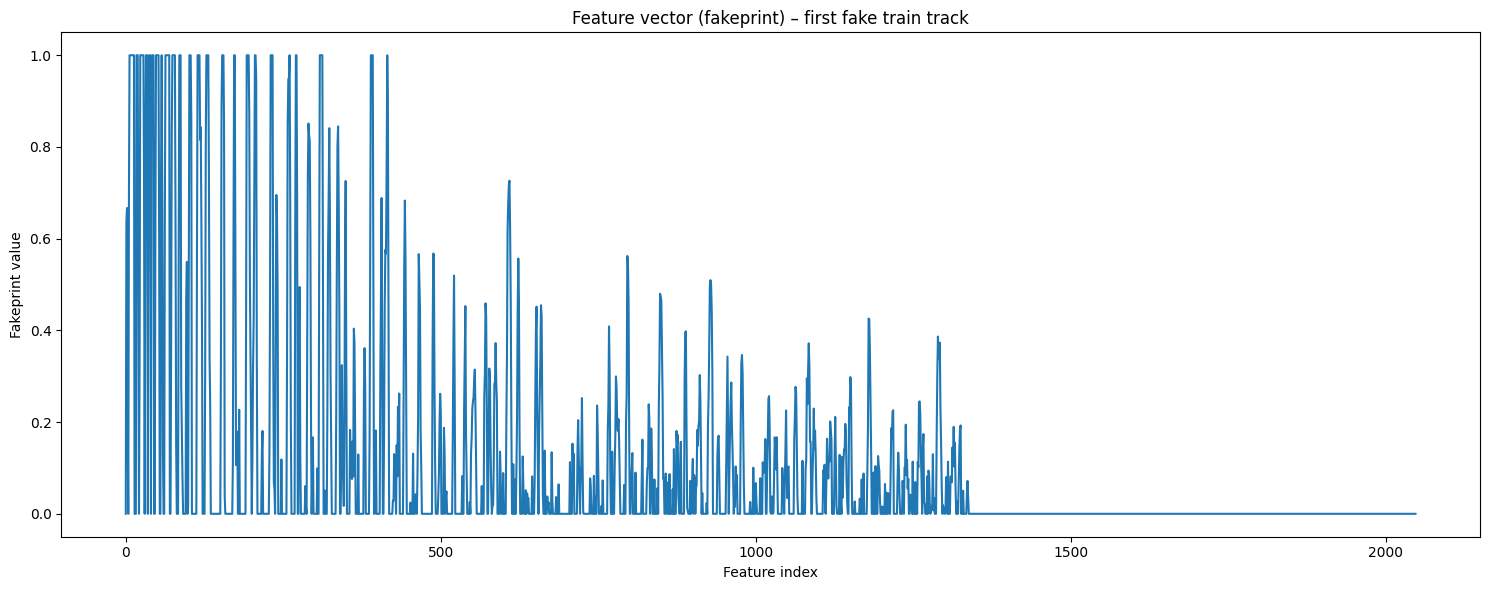

In [19]:
# Test compute_feature_vector on the first fake track

Fs = 22050
N = 4096
H = 1024

first_fake_audio = os.path.join(fake_path, fake_train[0])
f_vector = compute_feature_vector(first_fake_audio, Fs, N, H)

print("Feature vector shape:", f_vector.shape)
print("First 10 values of the feature vector:", f_vector[:10])

plt.figure(figsize = (15,6))
plt.plot(f_vector)
plt.xlabel("Feature index")
plt.ylabel("Fakeprint value")
plt.title("Feature vector (fakeprint) – first fake train track")
plt.tight_layout()
plt.show()

In [21]:
# Define labels_dict
labels_dict = {0: 'fake', 1: 'real'}

Fs = 22050
N = 4096
H = 1024

train_fvector = []
test_fvector = []
labels = []


def compute_feature_vectors_for_file_list(file_list, path, description, label_type = None):
    fvector = []
    labels_vector = []

    for file_name in tqdm(file_list, desc = description):
        file_path = os.path.join(path, file_name)
        f_vec = compute_feature_vector(file_path, Fs, N, H)
        fvector.append(f_vec)
        if label_type is not None:
            labels_vector.append(label_type)

    return fvector, labels_vector

In [22]:
# Compute the feature vector of the train set (fake + real audio tracks)

# Real tracks (label = 1)
real_fvector, real_labels = compute_feature_vectors_for_file_list(
    real_train,
    real_path,
    description = "Computing features (real training set)",
    label_type = 1
)

# Fake tracks (label = 0)
fake_fvector, fake_labels = compute_feature_vectors_for_file_list(
    fake_train,
    fake_path,
    description = "Computing features (fake training set)",
    label_type = 0
)

# Unite the two features vectors (real + fake)
train_fvector = fake_fvector + real_fvector

# and the labels vectors
labels = fake_labels + real_labels

# Compute feature vector of the test set (without labels)
test_fvector, _ = compute_feature_vectors_for_file_list(
    test_set,
    test_path,
    description = "Computing features (test)",
    label_type = None
)

Computing features (test): 100%|██████████| 515/515 [01:10<00:00,  7.31it/s]


In [23]:
# Print the information about the feature vectors and labels vector
print("Number of train vectors:", len(train_fvector))
print("Number of test vectors:", len(test_fvector))

print("Feature vector length:", train_fvector[0].shape[0])

print("Number of labels:", len(labels))

Number of train vectors: 970
Number of test vectors: 515
Feature vector length: 2048
Number of labels: 970


In [24]:
# Train regressor

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

x_train = np.vstack(train_fvector)
y_train = np.array(labels)

# 1. Instantiate the logisticRegression model 
logreg = LogisticRegression(class_weight = "balanced", max_iter = 1000)

# 2. Fit the model with train_fvector and labels
logreg.fit(x_train, y_train)

# 3. Prediction sul train set
y_pred_train = logreg.predict(x_train)

In [25]:
# 4. Calculate and print the accuracy
acc_train = accuracy_score(y_train, y_pred_train)
print("Train accuracy:", acc_train)

Train accuracy: 1.0


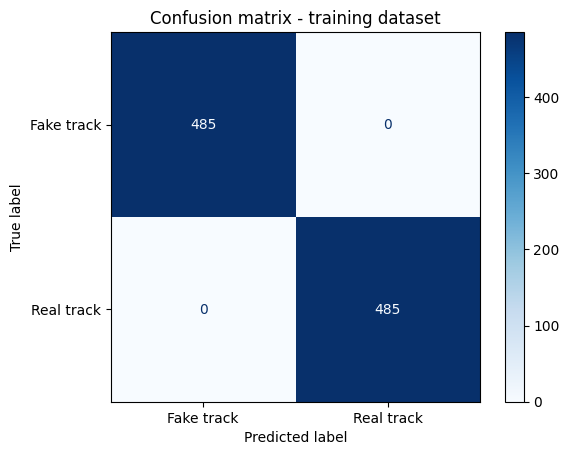

In [26]:
# 5. Confusion matrix
cm = confusion_matrix(y_train, y_pred_train)

disp = ConfusionMatrixDisplay(confusion_matrix = cm,
                              display_labels = ["Fake track", "Real track"])
disp.plot(cmap = "Blues")
plt.title("Confusion matrix - training dataset")
plt.show()

In [27]:
# Changing the threshold of the probability
proba_real = logreg.predict_proba(x_train)[:, 1]

# Threshold of 0.3
threshold = 0.3
y_pred_03 = (proba_real > threshold).astype(int)

# Threshold of 0.7
threshold = 0.7
y_pred_07 = (proba_real > threshold).astype(int)

In [28]:
# Threshold 0.3
acc_03 = accuracy_score(y_train, y_pred_03)
print("Threshold 0.3 - accuracy:", acc_03)

# Threshold 0.7
acc_07 = accuracy_score(y_train, y_pred_07)
print("Threshold 0.7 - accuracy:", acc_07)

Threshold 0.3 - accuracy: 1.0
Threshold 0.7 - accuracy: 1.0


## Question 4

In [29]:
# Compute prediction for the test set

x_test = np.vstack(test_fvector)

# Prediction on the test dataset (0 = fake, 1 = real)
y_pred_test = logreg.predict(x_test)

# Print tracks classified as 'real'
real_tracks = [file_name for file_name, y in zip(test_set, y_pred_test) if y == 1]
print('The real tracks are: \n')
for file_name in real_tracks:
    print(file_name)

print('\nTotal number of real tracks found: ', len(real_tracks))


The real tracks are: 

37437.mp3
38302.mp3
51890.mp3
52180.mp3
53966.mp3
54100.mp3

Total number of real tracks found:  6


In [30]:
# Find password
psw = 0

dates = []

for track in real_tracks:
    path = os.path.join(test_path, track) 
    try:
        audio = EasyID3(path)
        if 'date' in audio:
            d = int(audio['date'][0])
            print(track, "date:", d)
            dates.append(d)
    except Exception:
        continue # No date found

psw = sum(dates)

print('\nThe password is:', psw)

51890.mp3 date: 2001
52180.mp3 date: 1789
53966.mp3 date: 476
54100.mp3 date: 1492

The password is: 5758


In [31]:
# 1. Ground truth file information

ground_truth = pd.read_csv("sonics/ground_truth.csv")

print("Number of columns: ", len(ground_truth.columns.tolist()))
print("Columns:", ground_truth.columns.tolist())
print("Number of rows:", len(ground_truth))
print("Head of ground_truth.csv file", ground_truth.head())

Number of columns:  17
Columns: ['id', 'lyrics', 'algorithm', 'style', 'filename', 'bit_rate', 'duration', 'source', 'lyrics_feature', 'topic', 'genre', 'mood', 'label', 'target', 'skip_time', 'no_vocal', 'split']
Number of rows: 24733
Head of ground_truth.csv file       id                                             lyrics  \
0  54113  [Intro]\n(Whoah)\nStaring at the stars, lost i...   
1  53851  [Intro]\n(Whisper) Athena, goddess of the nigh...   
2  53853  [Verse 1]\nStaring at the mirror, don't recogn...   
3  53854  [Intro]\nIn the shadows of the night, where da...   
4  53855  [Verse 1]\nIn a darkened room, I sit alone,\nG...   

            algorithm                                              style  \
0          chirp-v3.5  male vocals, lounge, piano, saxophone, slow te...   
1          chirp-v3.5  female vocals, salsa, piano, trumpet, percussi...   
2            chirp-v3  male vocals, guitar, drums, bass, grunge, mode...   
3          chirp-v3.5  male vocals, electric guitar

In [33]:
# 2. Label of the real tracks found with the model

print("Predicted real tracks and their ground-truth labels:\n")

false_positives = []
true_real_tracks = []

for file_name in real_tracks:
    track_id = int(os.path.splitext(file_name)[0]) # Remove the extension from file name and cast it into int64 as in the .csv

    row = ground_truth.loc[ground_truth['id'] == track_id] # If the file name of the n-th predicted track is found in the .csv

    if len(row) == 0:
        print(file_name, "→ not found in ground_truth.csv")
        continue

    label = row['label'].iloc[0]
    print(file_name, "→", label) # Print the label in the .csv of the predicted real track

    if label == 'real':
        true_real_tracks.append(file_name) # Append to the true real tracks set
    else:
        false_positives.append(file_name) # Append to the false positive set

print("\nNumber of false positives:", len(false_positives))
print("False positives:")
for file_name in false_positives:
    print(file_name)

print("\nTrue real tracks (according to ground truth):")
for file_name in true_real_tracks:
    print(file_name)


Predicted real tracks and their ground-truth labels:

37437.mp3 → mostly fake
38302.mp3 → mostly fake
51890.mp3 → real
52180.mp3 → real
53966.mp3 → real
54100.mp3 → real

Number of false positives: 2
False positives:
37437.mp3
38302.mp3

True real tracks (according to ground truth):
51890.mp3
52180.mp3
53966.mp3
54100.mp3


In [34]:
# Creating the array of labels
y_test_true = []

ids_and_labels = ground_truth.copy() 
ids_and_labels['id'] = ids_and_labels['id'].astype(str).str.zfill(5)   

# Real = 1, otherwise = 0 
ids_and_labels['label'] = np.where(ids_and_labels['label'] == 'real', 1, 0)
ids_and_labels = ids_and_labels[['id', 'label']]

for file_name in test_set:
    track_id_str = os.path.splitext(file_name)[0]
    row = ids_and_labels.loc[ids_and_labels['id'] == track_id_str]

    if len(row) == 0:
        y_test_true.append(0)
    else:
        y_test_true.append(int(row['label'].iloc[0]))

y_test_true = np.array(y_test_true)

Test accuracy: 0.996116504854369
Test confusion matrix:
 [[509   2]
 [  0   4]]


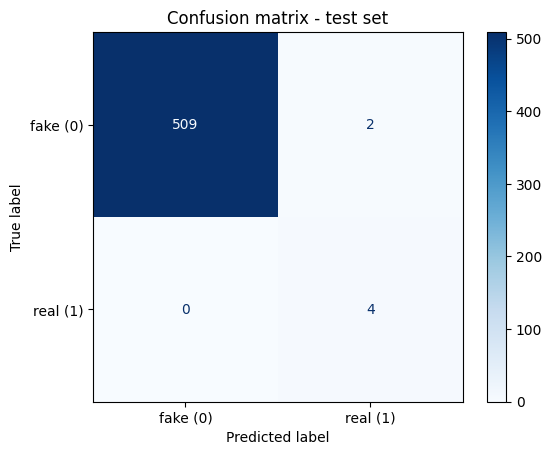

In [35]:
# Print the accuracy for the test set
acc_test = accuracy_score(y_test_true, y_pred_test)
print("Test accuracy:", acc_test)

# Plot the confusion matrix
cm = confusion_matrix(y_test_true, y_pred_test)
print("Test confusion matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix = cm,
                              display_labels = ["fake (0)", "real (1)"])
disp.plot(cmap = "Blues")
plt.title("Confusion matrix - test set")
plt.show()

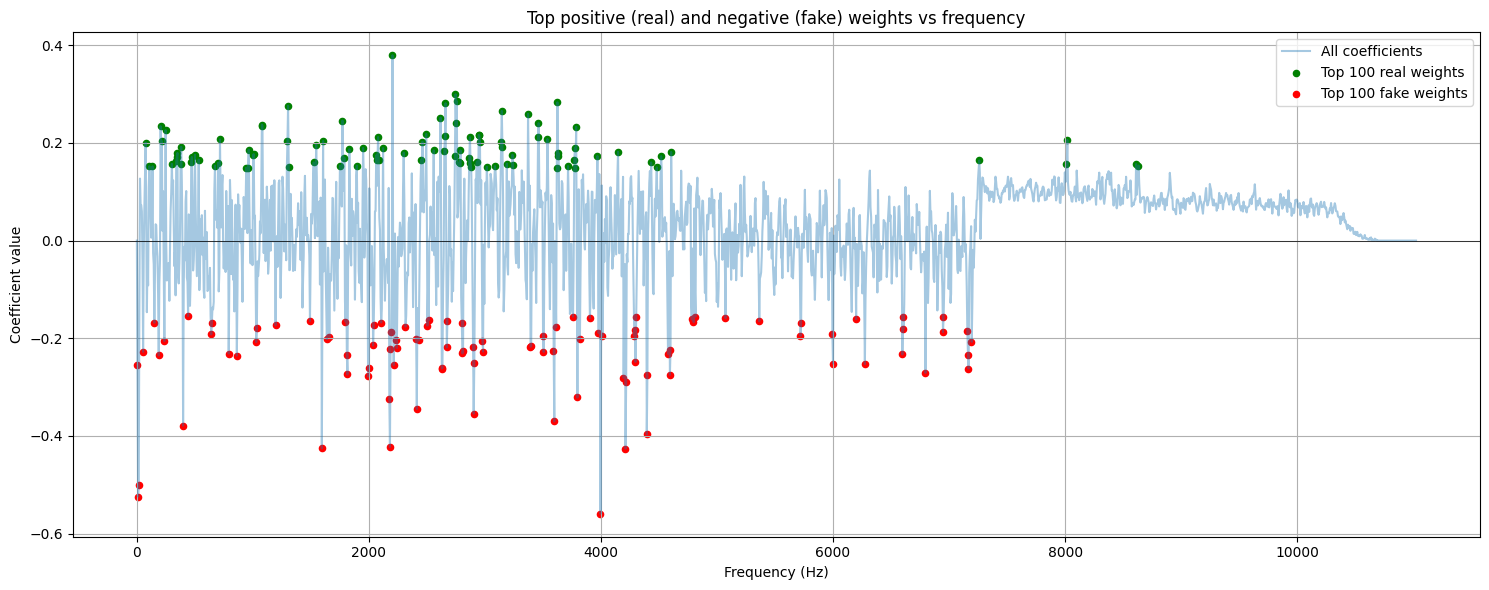

In [36]:
# Coefficients vector
w = logreg.coef_[0]

# Frequency axis for the plot
n_bins = len(w)
freq_axis = np.linspace(0, Fs / 2, n_bins)

# N most positive weights (real)
top_pos_idx = np.argsort(w)[-100:]

# N most negative weights (fake)
top_neg_idx = np.argsort(w)[:100]

plt.figure(figsize = (15,6))

# Plot all the coefficients
plt.plot(freq_axis, w, alpha = 0.4, label = "All coefficients")

# Plot of N most positive coeffs
plt.scatter(freqs[top_pos_idx], w[top_pos_idx],
            color = "green", s = 20, label = "Top 100 real weights")

# Plot of N most negative coeffs
plt.scatter(freqs[top_neg_idx], w[top_neg_idx],
            color = "red", s = 20, label = "Top 100 fake weights")

plt.axhline(0.0, color = "black", linewidth = 0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Coefficient value")
plt.title("Top positive (real) and negative (fake) weights vs frequency")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## Question 5

In [37]:
# 1. Plot the lyrics of the real tracks

print("Lyrics for real tracks:\n")

lyrics_list = []

for file_name in true_real_tracks:
    track_id = int(os.path.splitext(file_name)[0])
    row = ground_truth.loc[ground_truth['id'] == track_id]
    lyrics = row['lyrics_feature'].iloc[0]
    lyrics_list.append(lyrics)
    print(file_name, "→", lyrics)

Lyrics for real tracks:

51890.mp3 → Merry Christmas 
52180.mp3 → and a happy new year 
53966.mp3 → to you and 
54100.mp3 → your family 


In [38]:
# Find the key sentence
ordered_lyrics = [
    lyrics_list[0],
    lyrics_list[1],
    lyrics_list[2],
    lyrics_list[3],
]

key_sentence = "".join(ordered_lyrics)
print("\nKey sentence:")
print(key_sentence)



Key sentence:
Merry Christmas and a happy new year to you and your family 


In [39]:
# Listen to the real tracks

for file_name in true_real_tracks:
    path = os.path.join(test_path, file_name) 
    print(file_name)
    display(ipd.Audio(path, rate = Fs))